# SVM cuánticas: HHL y kernels cuánticos — código, experimentos y bases

**Computación cuántica · Universidad Técnica Federico Santa María**

Este notebook documenta el código de los dos experimentos propuestos en el informe de estado
del arte sobre *Quantum Machine Learning*: **qué hace cada pieza, por qué está hecha así y en qué
literatura se apoya**. Incluye además **resultados de prueba** (corridas rápidas o reducidas)
con el único fin de mostrar que el código funciona de punta a punta.

> **Aviso importante.** Los resultados de este documento vienen de corridas pequeñas: E1 con una
> grilla reducida (16 corridas) y E2 con una sola semilla (120 filas). **No son resultados
> finales, no llevan análisis estadístico y no permiten concluir nada sobre las hipótesis.**
> Los barridos completos están descritos en la sección 7 y todavía no se han ejecutado.

**Contenido**

1. Contexto y objetivo
2. Estructura del repositorio y flujo de trabajo
3. Experimento 1 — HHL sobre una LS-SVM pequeña
4. Resultados de prueba de E1
5. Experimento 2 — QSVC frente a SVC clásica
6. Resultados de prueba de E2
7. Reproducibilidad, limitaciones y trabajo pendiente
8. Referencias

## 1. Contexto y objetivo

El informe de estado del arte termina con dos afirmaciones sobre la máquina de vectores de soporte
(SVM) cuántica. Cada experimento está diseñado para ponerlas a prueba por separado:

| | Afirmación del informe | Experimento |
|---|---|---|
| **1** | La **SVM basada en HHL** tiene una aceleración teórica exponencial (Rebentrost et al., 2014) que depende de hardware tolerante a fallos y de qRAM. En la práctica solo se ha ejecutado en sistemas mínimos, es muy sensible al ruido y su costo real en circuitos es alto. | **E1:** implementar HHL a mano sobre una LS-SVM pequeña y medir sus **recursos** (profundidad, compuertas `cx`, qubits) y la **calidad** de la solución. |
| **2** | La **SVM con kernel cuántico (QSVC)** es ejecutable hoy, pero en estudios con validación estadística no supera a la SVM clásica en datos tabulares (Kakavand et al., 2026); su desempeño depende del ancho de banda o escala de las características (Shaydulin y Wild, 2022; Flórez et al., 2025). | **E2:** comparar QSVC y SVC clásicas con el **protocolo de Kakavand** y, como extensión propia, tratar la escala `s` como hiperparámetro. |

**Alcance de esta etapa.** Entregar código **reproducible**, parametrizado, que ejecute ambos
experimentos de punta a punta y deje **resultados crudos** en disco (CSV/JSON). El análisis, las
pruebas estadísticas y las conclusiones quedan para una etapa posterior.

**Todo es simulación** (`Statevector` y Aer). No se usa hardware real de IBM.

> **Ojo con una distinción.** Esto describe *este código*, no el artículo de Kakavand et al.: ese
> trabajo **sí incluye una validación en hardware real** (IBM `ibm_fez`, procesador Heron r2, seis
> experimentos con 1 024 *shots* por circuito y sin mitigación de errores de lectura; ver la sección 5.1).
> Aquí no se reproduce esa parte: los kernels cuánticos se calculan con `Statevector` y, opcionalmente,
> con un modelo de ruido simulado.

## 2. Estructura del repositorio y flujo de trabajo

```
Experimentos/
├── CLAUDE.md                  # especificación completa (decisiones, métricas, barridos)
├── README.md                  # estado actual e instrucciones de ejecución
├── requirements.txt           # versiones fijadas
├── notebooks/
│   ├── 01_hhl_lssvm.ipynb     # E1: LS-SVM, circuito HHL, recursos, pruebas, barrido
│   ├── 02_qsvc_vs_svc.ipynb   # E2: datos, kernels, CV anidada (C, s), pruebas, barrido
│   └── 03_informe.ipynb       # este documento
├── informe_data/              # resultados de prueba que muestra este informe
├── results/                   # salida de los barridos (no se versiona)
└── third_party/               # código de Kakavand, sin modificar (no se versiona)
```

**Decisión de diseño: el código vive en los notebooks.** No hay un paquete `src/` ni scripts
aparte: cada notebook define sus funciones, sus pruebas (celdas con `assert`) y el barrido. Cada uno
sigue el mismo esquema: configuración → utilidades (semillas, versiones, logging, *checkpoint*) →
funciones → pruebas → barrido → vista previa.

**Cómo leer este informe.** Los extractos de código de las secciones 3 y 5 **no están copiados a
mano**: una función auxiliar (siguiente celda) los lee de los notebooks 01 y 02, de modo que lo que
se ve aquí es siempre lo que realmente se ejecuta.

**Reutilización de Kakavand.** Para E2 se importa el paquete `qsvm_benchmark` (Kakavand et al.,
licencia CC BY 4.0) para cargar datasets, preprocesar, construir los mapas de características y
calcular los kernels cuánticos. **No se modifica**; solo se importa. E1 no lo usa.

In [1]:
import ast, json
from pathlib import Path

import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NOTEBOOKS = ROOT / "notebooks"

# Resultados de prueba que muestra este informe (versionados en el repositorio).
# Para usar otra corrida, cambiar estas dos rutas por carpetas de results/hhl o results/qsvc.
HHL_RESULTS = ROOT / "informe_data" / "hhl_demo"
QSVC_RESULTS = ROOT / "informe_data" / "qsvc_quick"

def func_source(nb_name, *names):
    """Código fuente de las funciones `names` tal como están definidas en un notebook."""
    found = {}
    nb = nbformat.read(NOTEBOOKS / nb_name, as_version=4)
    for c in nb.cells:
        if c.cell_type != "code":
            continue
        for node in ast.parse(c.source).body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                found[node.name] = ast.get_source_segment(c.source, node)
    missing = [n for n in names if n not in found]
    assert not missing, f"no encontradas en {nb_name}: {missing}"
    return "\n\n".join(found[n] for n in names)

def show(nb_name, *names):
    display(Markdown("```python\n" + func_source(nb_name, *names) + "\n```"))

print("E1 (demo):", HHL_RESULTS.exists(), "| E2 (rápida):", QSVC_RESULTS.exists())

E1 (demo): True | E2 (rápida): True


## 3. Experimento 1 — HHL sobre una LS-SVM pequeña

### 3.1 Base teórica

**LS-SVM.** La SVM clásica se entrena resolviendo un problema de programación cuadrática. La
*Least Squares SVM* (Suykens y Vandewalle, 1999) reemplaza las restricciones de desigualdad por
igualdades y, con ello, el entrenamiento se reduce a **resolver un sistema lineal**:

$$
F\begin{pmatrix} b \\ \alpha \end{pmatrix}=\begin{pmatrix} 0 \\ y \end{pmatrix},
\qquad
F=\begin{pmatrix} 0 & \mathbf 1^{\top} \\ \mathbf 1 & K+\gamma^{-1}I \end{pmatrix},
$$

donde $K_{ij}=k(x_i,x_j)$ es la matriz kernel, $y_i\in\{-1,+1\}$ y $\gamma$ regula el
compromiso entre ajuste y margen. El clasificador es $\operatorname{sign}\big(b+\sum_i\alpha_i\,k(x_i,x)\big)$.

**HHL.** El algoritmo de Harrow, Hassidim y Lloyd (2009) prepara el estado $|x\rangle\propto A^{-1}|b\rangle$
usando estimación de fase cuántica (QPE) para leer los valores propios de $A$, una rotación
condicionada para dividir cada componente por su valor propio, y la QPE inversa para limpiar el
registro auxiliar. **Rebentrost, Mohseni y Lloyd (2014)** aplican esta idea a la LS-SVM: la
matriz $F$ de arriba es exactamente el sistema que resuelven, y de ahí viene la aceleración
exponencial teórica que menciona el informe.

**Qué *no* demuestra este experimento.** Esa aceleración presupone qRAM, hardware tolerante a
fallos y que $e^{iFt}$ se pueda aplicar de forma eficiente. Aquí $e^{iFt}$ se **construye
clásicamente** a partir de la matriz densa $F$. Por lo tanto, la profundidad del circuito
simulado **no es evidencia de aceleración cuántica**: sirve para estimar el costo de un HHL
pequeño, no para medir ventaja.

### 3.2 Del problema de ML al sistema lineal

Los datos son una submuestra estratificada de `breast_cancer` (scikit-learn), estandarizada y
reducida con PCA a 2 componentes, ajustadas **solo con los puntos de entrenamiento**.
Con $N$ puntos de entrenamiento, $F$ es de $(N+1)\times(N+1)$:

- $N=3$ → $F$ de 4×4 (**2 qubits** de sistema); $N=7$ → 8×8 (**3 qubits**); $N=15$ → 16×16 (opcional).
- Si $N+1$ no es potencia de 2, $F$ se rellena con un **bloque identidad** y el lado derecho con ceros
  (los valores propios añadidos valen 1 y no alteran $[b;\alpha]$).
- Kernel lineal por defecto (como Rebentrost et al.); RBF opcional.

In [2]:
show("01_hhl_lssvm.ipynb", "build_lssvm", "solve_classical", "predict")

```python
def build_lssvm(X, y, gamma, kernel="linear"):
    # devuelve F (rellenada a potencia de 2) y el lado derecho rhs
    N = len(y)
    K = make_kernel(kernel, X)(X, X)
    F = np.zeros((N + 1, N + 1))
    F[0, 1:] = 1.0
    F[1:, 0] = 1.0
    F[1:, 1:] = K + np.eye(N) / gamma
    rhs = np.concatenate([[0.0], y])
    dim = 1 << int(np.ceil(np.log2(N + 1)))
    if dim > N + 1:                                 # relleno: bloque identidad y rhs con ceros
        Fp = np.eye(dim)
        Fp[: N + 1, : N + 1] = F
        F = Fp
        rhs = np.concatenate([rhs, np.zeros(dim - N - 1)])
    return F, rhs

def solve_classical(F, rhs):
    return np.linalg.solve(F, rhs)

def predict(x_vec, X_train, X_test, kernel="linear"):
    # sign(b + sum_i alpha_i k(x_i, x)); invariante a escala positiva del vector solución
    N = len(X_train)
    b, alpha = np.real(x_vec[0]), np.real(x_vec[1 : N + 1])
    s = b + make_kernel(kernel, X_train)(X_test, X_train) @ alpha
    return np.where(s >= 0, 1.0, -1.0)
```

### 3.3 El circuito HHL, paso a paso

$F$ es simétrica pero **indefinida**: tiene exactamente un valor propio negativo (la fila y
columna de unos, junto a $K+\gamma^{-1}I$ definida positiva, lo producen). Eso condiciona el diseño:

1. **Preparación de $|b\rangle$** normalizado con `StatePreparation`.
2. **QPE** con $n_c$ qubits de reloj sobre $U=e^{iFt}$. Hay dos modos:
   - `exact`: `UnitaryGate(expm(1j·F·t·2^j))` controlada, una por qubit de reloj.
   - `trotter`: `PauliEvolutionGate` de `SparsePauliOp.from_operator(F)` con Suzuki–Trotter
     (orden y pasos configurables; para $U^{2^j}$ se usan `reps·2^j` pasos). Da una profundidad más realista.
3. **Rotación condicionada** sobre un ancilla. Para cada valor $k\neq0$ del reloj, una RY multicontrolada
   con ángulo $2\arcsin(C/\tilde\lambda_k)$, con $C=\min|\tilde\lambda_k|$; para $k=0$ no hay rotación.
4. **QPE inversa.**
5. **Postselección** ancilla = 1 y reloj = 0; el vector solución se extrae de la `Statevector`
   (no por muestreo).

**Complemento a dos.** Como hay un valor propio negativo, el reloj se interpreta con signo: el valor
$c\in[0,2^{n_c})$ representa $k=c$ si $c<2^{n_c-1}$ y $k=c-2^{n_c}$ en otro caso, con
$\tilde\lambda_k = 2\pi k/(2^{n_c}t)$.

**Elección de $t$.** El mayor $|\lambda|$ debe caer dentro del rango representable de la fase
$[-2^{n_c-1},\,2^{n_c-1}-1]/2^{n_c}$. Se usa $t=2\pi\,\dfrac{2^{n_c-1}-1}{2^{n_c}\,\max|\lambda|}$.

**Costo de la rotación.** Esta implementación usa $2^{n_c}-1$ compuertas multicontroladas, es decir,
**es exponencial en $n_c$**; es aceptable para $n_c\le 6$ y no escala más allá.

In [3]:
show("01_hhl_lssvm.ipynb", "choose_t", "clock_to_k", "build_hhl_circuit", "hhl_solve", "align_phase")

```python
def choose_t(F, n_c):
    lam_max = np.max(np.abs(np.linalg.eigvalsh(F)))
    return 2 * np.pi * ((2 ** (n_c - 1) - 1) / 2 ** n_c) / lam_max

def clock_to_k(c, n_c):
    return c if c < 2 ** (n_c - 1) else c - 2 ** n_c

def build_hhl_circuit(F, b, n_c, mode="exact", t=None, trotter_order=2, trotter_reps=1):
    dim = F.shape[0]
    n_s = int(np.log2(dim))
    assert 2 ** n_s == dim, "F debe ser de lado potencia de 2"
    if t is None:
        t = choose_t(F, n_c)
    n_sys_clk = n_s + n_c
    sys_q = list(range(n_s))
    clk_q = list(range(n_s, n_s + n_c))

    qpe = QuantumCircuit(n_sys_clk, name="QPE")
    qpe.h(clk_q)
    for j in range(n_c):
        cg = _controlled_power(F, t, j, mode, trotter_order, trotter_reps)
        qpe.append(cg, [clk_q[j]] + sys_q)
    qpe.append(QFTGate(n_c).inverse(), clk_q)

    qr_s, qr_c, qr_a = QuantumRegister(n_s, "s"), QuantumRegister(n_c, "c"), QuantumRegister(1, "a")
    qc = QuantumCircuit(qr_s, qr_c, qr_a)
    qc.append(StatePreparation(b / np.linalg.norm(b)), sys_q)
    qc.compose(qpe, qubits=range(n_sys_clk), inplace=True)
    for c in range(1, 2 ** n_c):
        k = clock_to_k(c, n_c)
        theta = 2 * np.arcsin(1.0 / k)              # C / lambda_k = 1/k
        qc.append(RYGate(theta).control(n_c, ctrl_state=c), clk_q + [n_sys_clk])
    qc.compose(qpe.inverse(), qubits=range(n_sys_clk), inplace=True)
    meta = dict(t=t, n_s=n_s, n_c=n_c, n_total=n_sys_clk + 1)
    return qc, meta

def hhl_solve(F, b, n_c, mode="exact", t=None, trotter_order=2, trotter_reps=1):
    qc, meta = build_hhl_circuit(F, b, n_c, mode, t, trotter_order, trotter_reps)
    sv = Statevector(qc).data
    off = 2 ** (meta["n_s"] + n_c)                  # ancilla=1, reloj=0
    v = sv[off : off + 2 ** meta["n_s"]]
    return dict(v=v, success_prob=float(np.vdot(v, v).real), qc=qc, **meta)

def align_phase(v, x_ref):
    # La fase global de HHL no es observable; se alinea con la solución clásica solo para
    # comparar componentes (imag_residual) y el signo global al clasificar.
    xv = v / np.linalg.norm(v)
    ov = np.vdot(x_ref, xv)
    return xv * np.conj(ov / abs(ov))
```

**Sobre la fase global.** La fase global de un estado cuántico no es observable. Por eso `align_phase`
rota el vector de HHL para que su producto interno con la solución clásica sea real y positivo; se usa
solo para comparar componentes y para fijar el signo global al clasificar.

### 3.4 Recursos y métricas

Cada corrida produce una fila con:

- **Recursos**, tras transpilar a `["sx", "rz", "cx"]` con `optimization_level=1` y semilla fija:
  profundidad (antes y después), número de compuertas por tipo y `cx_count`.
- **Calidad de la solución:** `success_prob` (probabilidad de la postselección) y
  `fidelity` $=|\langle x_{\text{HHL}}|x_{\text{clásico}}\rangle|^2$ con ambos normalizados, más la parte
  imaginaria residual.
- **Utilidad como clasificador:** `acc_hhl`, `acc_classical` y `agreement` en un conjunto de prueba pequeño.
- Además, $\kappa$ (número de condición de $F$), sus valores propios y el tiempo de ejecución.
- **Ruido (opcional):** Aer con matriz de densidad y error depolarizante (1q = 0.001, 2q = 0.01), solo para $N=3$.

In [4]:
show("01_hhl_lssvm.ipynb", "count_resources")

```python
def count_resources(qc, seed):
    tqc = transpile(qc, basis_gates=BASIS, optimization_level=1, seed_transpiler=seed)
    ops = dict(tqc.count_ops())
    return tqc, dict(depth_pre=qc.depth(), depth_post=tqc.depth(), size_post=tqc.size(),
                     cx_count=int(ops.get("cx", 0)), gate_counts=json.dumps(ops, sort_keys=True))
```

### 3.5 Pruebas del experimento

El notebook 01 incluye cuatro pruebas con `assert`. Las tres primeras son las pedidas en la
especificación; la cuarta se agregó al encontrar un error:

1. **LS-SVM clásica:** coincide con `np.linalg.solve`, clasifica bien el entrenamiento en un caso
   separable y $F$ tiene exactamente un valor propio negativo.
2. **HHL en una diagonal 4×4** con valores propios exactamente representables (incluido uno negativo):
   `fidelity > 0.999` (se obtiene 1.0). Valida el orden de bits de la QPE, el complemento a dos y el signo.
3. **$N=3$, $n_c=6$, `exact`:** fidelidad alta. Se verifica con $\gamma=10$ (≈ 0.99).
4. **Modo `trotter` realmente simulado:** difiere de `exact`, su error baja al aumentar los pasos y la
   transpilación conserva el estado.

**Dos hallazgos de la verificación** (documentados, no son conclusiones del estudio):

- **La fidelidad depende de $\kappa$ y de $n_c$.** Con $\gamma=1$ y $n_c=6$ la fidelidad era 0.69. No era un
  error: la solución concentra su peso en los valores propios más pequeños, que con $\kappa\approx56$ caen
  por debajo de la resolución del reloj ($k<1$) y no reciben rotación. Con $n_c=7$ la fidelidad sube a 0.998.
- **Un error corregido en el modo `trotter`.** Al principio daba exactamente lo mismo que `exact`: `Statevector`
  evaluaba la compuerta de Trotter controlada con su matriz exacta, mientras los recursos sí contaban la
  síntesis de Trotter. Ahora se decompone explícitamente (ver `_controlled_power`), y la prueba 4 lo vigila.

In [5]:
show("01_hhl_lssvm.ipynb", "_controlled_power")

```python
def _controlled_power(F, t, j, mode, trotter_order, trotter_reps):
    # U^(2^j) = exp(i F t 2^j), controlada por un qubit
    if mode == "exact":
        return UnitaryGate(sla.expm(1j * t * (2 ** j) * F), label=f"U^{2**j}").control(1)
    if mode == "trotter":
        op = SparsePauliOp.from_operator(F).simplify()
        op = SparsePauliOp(op.paulis, np.real(op.coeffs))
        synth = SuzukiTrotter(order=trotter_order, reps=trotter_reps * 2 ** j)
        # PauliEvolutionGate implementa exp(-i H time) -> tiempo negativo para exp(+i F t)
        evo = PauliEvolutionGate(op, time=-t * (2 ** j), synthesis=synth)
        # Se decompone UNA vez para fijar la síntesis de Trotter en una compuerta con definición.
        # Si no, Statevector evalúa la PauliEvolutionGate controlada con su matriz exacta y la
        # simulación sería idéntica a `exact` (solo los recursos reflejarían Trotter).
        sub = QuantumCircuit(op.num_qubits)
        sub.append(evo, range(op.num_qubits))
        return sub.decompose().to_gate(label=f"Trotter U^{2**j}").control(1)
    raise ValueError(mode)
```

## 4. Resultados de prueba de E1

> **Corridas de prueba, no definitivas.** Grilla reducida: $N=3$, $n_c\in\{3,4,5,6\}$,
> $\gamma\in\{1,10\}$, modos `exact` y `trotter`, una sola semilla (16 corridas). Se obtuvo ejecutando
> el notebook 01 con esa grilla en lugar de la rápida. El barrido completo (144 corridas) no se ha ejecutado.

In [6]:
hhl = pd.read_csv(HHL_RESULTS / "runs.csv")
meta = json.loads((HHL_RESULTS / "config.json").read_text(encoding="utf-8"))
print(f"{len(hhl)} corridas | qiskit {meta['versions']['qiskit']} | python {meta['python']} | {meta['date']}")
cols = ["n_clock", "gamma", "mode", "kappa", "n_total_qubits", "depth_pre", "depth_post", "cx_count",
        "success_prob", "fidelity", "acc_hhl", "acc_classical", "agreement", "wall_time_s"]
hhl[cols].round(4)

16 corridas | qiskit 2.3.0 | python 3.12.10 | 2026-11-03T09:43:13


,n_clock,gamma,mode,kappa,n_total_qubits,depth_pre,depth_post,cx_count,success_prob,fidelity,acc_hhl,acc_classical,agreement,wall_time_s
0,3,1,exact,56.3622,6,17,776,219,0.1093,0.0059,0.875,0.875,0.900,0.0545
1,3,1,trotter,56.3622,6,17,5919,2539,0.1046,0.0148,0.875,0.875,0.900,0.1805
2,3,10,exact,43.0999,6,17,776,219,0.1080,0.0060,0.875,0.875,0.900,0.0535
3,3,10,trotter,43.0999,6,17,5919,2539,0.1035,0.0150,0.875,0.875,0.900,0.2522
4,4,1,exact,56.3622,7,27,1064,477,0.0225,0.0168,0.875,0.875,0.900,0.0893
5,4,1,trotter,56.3622,7,27,12323,5497,0.0197,0.0704,0.850,0.875,0.925,0.3811
6,4,10,exact,43.0999,7,27,1064,477,0.0226,0.0145,0.875,0.875,0.900,0.0851
7,4,10,trotter,43.0999,7,27,12323,5497,0.0187,0.0549,0.850,0.875,0.925,0.3758
8,5,1,exact,56.3622,8,45,2444,1393,0.0129,0.3752,0.875,0.875,0.900,0.1769
9,5,1,trotter,56.3622,8,45,26059,11833,0.0475,0.2693,0.850,0.875,0.925,0.8724


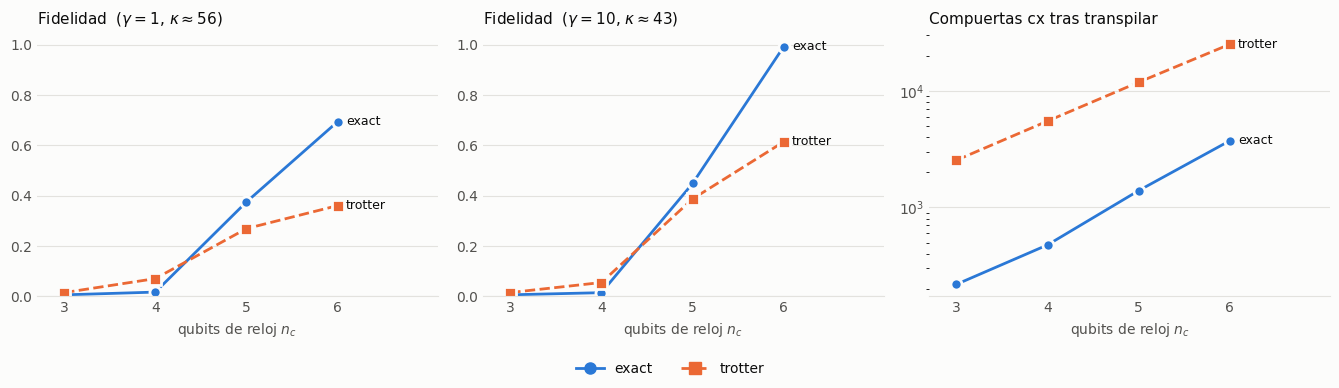

In [7]:
# Figura: calidad de la solución (fidelidad) y costo en compuertas cx frente a n_c.
# Colores: ranuras 1 y 2 de la paleta categórica de referencia; el modo se distingue además por
# marcador y trazo, de modo que no depende solo del color.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2de"
STYLE = {"exact":   dict(color="#2a78d6", marker="o", ls="-"),
         "trotter": dict(color="#eb6834", marker="s", ls="--")}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), facecolor=SURFACE)
for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.8)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK2, length=0)
    ax.set_xticks(sorted(hhl["n_clock"].unique()))
    ax.set_xlabel("qubits de reloj $n_c$", color=INK2)

for ax, g in zip(axes[:2], sorted(hhl["gamma"].unique())):
    for mode, st in STYLE.items():
        d = hhl[(hhl["gamma"] == g) & (hhl["mode"] == mode)].sort_values("n_clock")
        ax.plot(d["n_clock"], d["fidelity"], lw=2, ms=8, mec=SURFACE, mew=2, **st)
        ax.annotate(mode, (d["n_clock"].iloc[-1], d["fidelity"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", color=INK, fontsize=9, va="center")
    kap = hhl.loc[hhl["gamma"] == g, "kappa"].iloc[0]
    ax.set_title(f"Fidelidad  ($\\gamma={g:g}$, $\\kappa\\approx{kap:.0f}$)", color=INK, loc="left", fontsize=11)
    ax.set_ylim(0, 1.05)
    ax.set_xlim(axes[0].get_xticks()[0] - 0.3, axes[0].get_xticks()[-1] + 1.1)

ax = axes[2]
d1 = hhl[hhl["gamma"] == hhl["gamma"].min()]      # cx_count no depende de gamma (misma estructura)
for mode, st in STYLE.items():
    d = d1[d1["mode"] == mode].sort_values("n_clock")
    ax.plot(d["n_clock"], d["cx_count"], lw=2, ms=8, mec=SURFACE, mew=2, **st)
    ax.annotate(mode, (d["n_clock"].iloc[-1], d["cx_count"].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", color=INK, fontsize=9, va="center")
ax.set_yscale("log")
ax.set_title("Compuertas cx tras transpilar", color=INK, loc="left", fontsize=11)
ax.set_xlim(axes[0].get_xticks()[0] - 0.3, axes[0].get_xticks()[-1] + 1.1)

handles = [plt.Line2D([], [], lw=2, ms=8, **st, label=m) for m, st in STYLE.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, labelcolor=INK)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Qué muestra la figura (descripción, sin interpretar).** A la izquierda, la fidelidad de la solución
frente a $n_c$ para dos valores de $\gamma$ (es decir, de $\kappa$); a la derecha, el número de compuertas
`cx` de los circuitos transpilados. Es una sola semilla y un solo $N$: sirve para comprobar que el
experimento produce las métricas esperadas, no para comparar modos ni extraer tendencias.

## 5. Experimento 2 — QSVC frente a SVC clásica

### 5.1 Base teórica

**SVM con kernel.** Una SVM solo necesita la matriz kernel $K_{ij}=k(x_i,x_j)$. En scikit-learn esto se
entrega con `SVC(kernel="precomputed")`, de modo que la misma SVM sirve para kernels clásicos y cuánticos.

**Kernel cuántico de fidelidad.** Un mapa de características cuántico $x\mapsto|\phi(x)\rangle=U(x)|0\rangle$
induce el kernel (Havlíček et al., 2019)

$$
k(x,x') = \big|\langle\phi(x)|\phi(x')\rangle\big|^2 .
$$

Aquí se calcula **exactamente con `Statevector`** (sin ruido de muestreo). Se usan dos mapas de Kakavand et al.:

| Mapa | Descripción | Qubits |
|---|---|---|
| `zzfm` | `ZZFeatureMap` (Havlíček et al.): evolución de Pauli-Z de segundo orden, **con entrelazamiento** | uno por *feature* |
| `rot2dof` | Rotaciones `RX·RZ`, dos *features* por qubit, **sin entrelazamiento** | $\lceil n/2\rceil$ |

Ambos con `reps = 2`. Los kernels clásicos de referencia son `rbf` (con $\gamma$ = `'scale'` de
scikit-learn) y `linear`.

**Ancho de banda.** Shaydulin y Wild (2022) muestran que el desempeño de un kernel cuántico depende de su
ancho de banda, es decir, de la escala de las características que entra al circuito. Flórez et al. (2025)
vuelven sobre esa dependencia. Kakavand et al. (2026) ajustan solo la regularización $C$ y proponen un
"*bandwidth-aware encoding*" como trabajo futuro (Sec. 7 de su artículo).

**Alcance del estudio de Kakavand et al.** Según su resumen: nueve datasets binarios, cuatro mapas de
características cuánticos, tres kernels clásicos y varios modelos de ruido (970 experimentos con
validación cruzada anidada estricta); **ninguna de las 29 comparaciones pareadas cuántico–clásico alcanza
significancia a $\alpha=0.05$**; y una **validación en hardware real** (IBM `ibm_fez`, Heron r2) con
correlación de kernel $r\ge0.976$ frente a la simulación en seis experimentos. Su código incluye el
ejecutor de hardware (`scripts/phase3_hardware_runner.py`, requiere acceso a IBM Quantum), que **este
proyecto no usa**. Sus seis experimentos de hardware usan los mapas `belis` y `rot2dof` sobre `breast_cancer`
(NMF, $k=10$), `sonar` (PCA, $k=6$) y `diabetes Pima` (NMF, $k=6$); en HW-01 a HW-04 la submuestra es
de $n=60$. Difieren de E2 en datasets, reducción y tamaño, así que no son comparables directamente con E2.

### 5.2 Protocolo de evaluación

**Datasets** (cargados con el `DatasetRegistry` de Kakavand):

| Dataset | Muestras | *Features* | Preprocesamiento | Qubits (`zzfm` / `rot2dof`) |
|---|---|---|---|---|
| `breast_cancer` | 569 | 30 | estandarizar + PCA $k=4$ | 4 / 2 |
| `banknote` | 1372 → **300** (submuestra estratificada) | 4 | estandarizar + PCA $k=4$ | 4 / 2 |
| `haberman` | 306 | 3 | estandarizar + PCA $k=3$ | 3 / 2 |

**Validación cruzada anidada, estratificada, 5 pliegues externos × 3 internos:**

```
para cada semilla y cada pliegue externo:
    1. preprocesar (escalar + PCA), AJUSTADO SOLO con el entrenamiento externo   <- sin fuga de datos
    2. para cada kernel y cada valor de s necesario: calcular K_train y K_test una vez
    3. CV interna (3 pliegues): elegir (C, s) con mayor exactitud balanceada media
    4. reentrenar SVC(kernel="precomputed") con (C, s) sobre todo el entrenamiento externo
    5. evaluar en el test externo  ->  una fila de resultados
```

La métrica de selección y de reporte es la **exactitud balanceada**, con $C\in\{0.01,0.1,1,10,100\}$ y
semillas que cambian las particiones y la submuestra. La matriz kernel se calcula por pliegue y por
$s$ y se **reutiliza para todos los $C$**; las cuánticas se guardan en disco con una clave `xxhash`.

**No se usa `run_nested_cv` de Kakavand**: recibe un kernel calculado sobre datos preprocesados
globalmente (con fuga) y solo ajusta $C$. El bucle propio sigue a su `run_nested_cv_leakage_free`.

### 5.3 Dos modos: protocolo original y extensión propia

| Modo | Qué se ajusta | Origen |
|---|---|---|
| `kakavand` | solo $C$, con $s=1$ fijo | **Protocolo de Kakavand et al. (2026)** |
| `scale_tuned` | $C$ **y** la escala $s\in\{0.1,0.25,0.5,1,2\}$ de forma conjunta | **Extensión propia**, motivada por Shaydulin y Wild (2022) y Flórez et al. (2025) |

> **El ajuste de $s$ no es parte del protocolo de Kakavand.** Él ajusta únicamente $C$ y propone la
> codificación sensible al ancho de banda como trabajo futuro. Atribuirle el ajuste de $s$ sería incorrecto.

**Qué es $s$.** Tras el preprocesamiento, $x\to s\cdot x$ antes de calcular el kernel. En el RBF equivale a
multiplicar $\gamma$ por $s^2$ (con $\gamma$ fijado sobre los datos a escala 1), lo que mantiene la
comparación justa con los kernels cuánticos. En el kernel lineal $s$ solo reescalaría $C$, por lo que no
se aplica.

In [8]:
show("02_qsvc_vs_svc.ipynb", "preprocess_fold", "s_values", "kernel_matrices")

```python
def preprocess_fold(X_tr, y_tr, X_te, spec, seed):
    # pipeline nuevo por pliegue externo, ajustado solo con X_tr
    pp = build_preprocessor(scaler=spec["scaler"], reducer=spec["reducer"],
                            k_features=spec["k"], random_state=seed)
    res = pp.fit_transform(X_tr, y_tr, X_te, np.zeros(len(X_te)))
    return res.X_train, res.X_test, pp

def s_values(kernel, mode, cfg):
    if mode == "kakavand" or kernel == "linear":
        return [1.0]
    if mode == "scale_tuned":
        return list(cfg["s_grid"])
    raise ValueError(mode)

def kernel_matrices(kernel, X_tr, X_te, s, cfg, seed, cache=None):
    """K(X_tr, X_tr) y K(X_te, X_tr) para la escala s. Devuelve (K_tr, K_te, compute_time_s, cache_hit)."""
    Xs_tr, Xs_te = s * X_tr, s * X_te
    if kernel == "linear":
        t0 = time.time()
        lk = LinearKernel()
        return lk.compute(X_tr), lk.compute(X_te, X_tr), time.time() - t0, False
    if kernel == "rbf":
        t0 = time.time()
        g = gamma_scale(X_tr)              # 'scale' sobre el entrenamiento a escala 1 -> gamma·s²
        return rbf_kernel(Xs_tr, gamma=g), rbf_kernel(Xs_te, Xs_tr, gamma=g), time.time() - t0, False

    key_cfg = dict(kernel=kernel, reps=cfg["reps"])
    if kernel.endswith("_noisy"):
        key_cfg.update(noise=cfg["noise"], seed=seed)
    key = compute_kernel_hash(np.ascontiguousarray(Xs_tr), np.ascontiguousarray(Xs_te), key_cfg)
    if cache is not None:
        hit = cache.load(key)
        if hit is not None:
            K_tr, K_te, meta = hit
            return K_tr, K_te, float(meta.get("compute_time_s", np.nan)), True
    t0 = time.time()
    K_tr, K_te = _quantum_matrices(kernel, Xs_tr, Xs_te, cfg, seed)
    dt = time.time() - t0
    if cache is not None:
        cache.save(key, K_tr, K_te, metadata=dict(compute_time_s=dt, **key_cfg))
    return K_tr, K_te, dt, False
```

In [9]:
show("02_qsvc_vs_svc.ipynb", "inner_search", "evaluate_fold")

```python
def inner_search(K_by_s, y_tr, inner_splits, C_grid):
    """Búsqueda en rejilla (s, C) sobre la CV interna. K_by_s: {s: K_tr} ya ordenado para el desempate."""
    best = (None, None, -np.inf)
    for s, K in K_by_s.items():
        for C in C_grid:
            scores = []
            for a, b in inner_splits:
                clf = SVC(kernel="precomputed", C=C).fit(K[np.ix_(a, a)], y_tr[a])
                scores.append(balanced_accuracy_score(y_tr[b], clf.predict(K[np.ix_(b, a)])))
            m = float(np.mean(scores))
            if m > best[2]:
                best = (C, s, m)
    return best

def evaluate_fold(X_tr, y_tr, X_te, y_te, kernel, modes, seed, cfg, cache=None):
    """Evalúa un kernel en un pliegue externo (datos ya preprocesados). Devuelve {mode: dict}."""
    inner = list(StratifiedKFold(cfg["n_inner"], shuffle=True, random_state=seed)
                 .split(np.zeros(len(y_tr)), y_tr))
    order = [1.0] + [s for s in cfg["s_grid"] if s != 1.0]          # orden de desempate
    needed = [s for s in order if any(s in s_values(kernel, m, cfg) for m in modes)]
    mats = {}
    for s in needed:
        mats[s] = kernel_matrices(kernel, X_tr, X_te, s, cfg, seed, cache)
    out = {}
    for mode in modes:
        t0 = time.time()
        svals = [s for s in needed if s in s_values(kernel, mode, cfg)]   # conserva el orden de desempate
        C, s, score = inner_search({s_: mats[s_][0] for s_ in svals}, y_tr, inner, cfg["C_grid"])
        K_tr, K_te = mats[s][0], mats[s][1]
        clf = SVC(kernel="precomputed", C=C).fit(K_tr, y_tr)
        y_pred = clf.predict(K_te)
        out[mode] = dict(
            best_C=C, best_s=s, inner_cv_score=score,
            balanced_accuracy=float(balanced_accuracy_score(y_te, y_pred)),
            accuracy=float(accuracy_score(y_te, y_pred)),
            n_kernel_evals=len(svals) * n_gram_entries(len(y_tr), len(y_te)),
            kernel_time_s=float(sum(mats[s_][2] for s_ in svals)),
            kernel_cache_hit=bool(all(mats[s_][3] for s_ in svals)),
            fit_time_s=time.time() - t0,
        )
    return out
```

### 5.4 Pruebas del experimento

El notebook 02 incluye cinco pruebas con `assert`:

1. **Sin fuga:** el escalador y la PCA se ajustan solo con el entrenamiento; alterar el test no cambia la
   transformación del entrenamiento.
2. **Smoke test de Kakavand** con el RBF (`breast_cancer`, PCA $k=4$, CV 2×2): exactitud balanceada
   ≈ 0.945 (tolerancia 0.01).
3. **Propiedades de las matrices kernel:** simétricas, diagonal 1 (cuánticas y RBF) y semidefinidas positivas.
4. **Equivalencia con Qiskit ML** (`FidelityQuantumKernel` / `QSVC`).
5. **Equivalencia con el runner de Kakavand:** en modo `kakavand` y con `zzfm`, el bucle propio reproduce
   pliegue a pliegue el `C` elegido y la exactitud balanceada.

**Hallazgos de la verificación** (documentados, no son conclusiones del estudio):

- **RBF.** El `RBFKernel` de Kakavand recalcula $\gamma$ con el primer argumento: en $K(X_\text{test},X_\text{train})$
  usa la varianza del *test*. Aquí $\gamma$ se fija con el entrenamiento, como pide la especificación, y por eso
  el smoke test da 0.9384 en lugar de 0.9450. Con el $\gamma$ de Kakavand, el bucle propio da exactamente 0.9450.
- **Qiskit ML.** `qiskit-machine-learning` 0.8.2 no se puede importar con `qiskit` 2.3, así que la prueba 4 se
  **omite**. En su lugar se verifica el kernel contra el circuito *compute–uncompute* $U^\dagger(x')U(x)$
  ($\max|\Delta K|\approx10^{-15}$).
- **Desempate.** En la CV interna gana el primer $(C,s)$ con la mejor media, probando $s=1$ primero.
- **Ruido (opcional).** Con `NOISE = True` se agregan kernels `*_noisy` (matriz de densidad, depolarizante).
  Su diagonal es la pureza de $\rho(x)$, no 1.

## 6. Resultados de prueba de E2

> **Corrida rápida, no definitiva.** Una sola semilla (0), 3 datasets × 4 kernels × 5 pliegues externos ×
> 2 modos = **120 filas**. El barrido completo usa 5 semillas (600 filas) y no se ha ejecutado.
> Con un solo conjunto de particiones **no hay base para comparar kernels ni para concluir sobre las
> hipótesis**; los valores solo muestran que el flujo completo funciona.

In [10]:
q = pd.read_csv(QSVC_RESULTS / "runs.csv")
qmeta = json.loads((QSVC_RESULTS / "config.json").read_text(encoding="utf-8"))
print(f"{len(q)} filas | semillas {[int(x) for x in sorted(q['seed'].unique())]} | qiskit {qmeta['versions']['qiskit']} | {qmeta['date']}")
print("filas por (dataset, kernel, modo):", q.groupby(["dataset", "kernel", "mode"]).size().unique().tolist(), "(= pliegues externos)")
q.head(6)[["dataset", "kernel", "mode", "seed", "outer_fold", "n_qubits", "best_C", "best_s",
           "balanced_accuracy", "accuracy", "n_train", "n_test"]]

120 filas | semillas [0] | qiskit 2.3.0 | 2026-11-03T09:42:37
filas por (dataset, kernel, modo): [5] (= pliegues externos)


,dataset,kernel,mode,seed,outer_fold,n_qubits,best_C,best_s,balanced_accuracy,accuracy,n_train,n_test
0,breast_cancer,zzfm,kakavand,0,0,4.0,10.0,1.00,0.407141,0.438596,455,114
1,breast_cancer,zzfm,scale_tuned,0,0,4.0,10.0,0.10,0.853095,0.868421,455,114
2,breast_cancer,rot2dof,kakavand,0,0,2.0,10.0,1.00,0.541598,0.640351,455,114
3,breast_cancer,rot2dof,scale_tuned,0,0,2.0,100.0,0.25,0.713888,0.780702,455,114
4,breast_cancer,rbf,kakavand,0,0,NaN,10.0,1.00,0.934818,0.947368,455,114
5,breast_cancer,rbf,scale_tuned,0,0,NaN,100.0,0.10,0.923190,0.938596,455,114


In [11]:
# Exactitud balanceada media sobre los 5 pliegues externos de la semilla 0 (solo para ver que el flujo funciona)
tabla = (q.pivot_table(index=["dataset", "mode"], columns="kernel", values="balanced_accuracy", aggfunc="mean")
          [["linear", "rbf", "rot2dof", "zzfm"]])
tabla.round(4)

kernel                     linear     rbf  rot2dof    zzfm
dataset       mode                                        
banknote      kakavand     0.9848  1.0000   0.6716  0.5972
              scale_tuned  0.9848  1.0000   0.6875  0.9941
breast_cancer kakavand     0.9529  0.9496   0.5343  0.4671
              scale_tuned  0.9529  0.9529   0.7318  0.8460
haberman      kakavand     0.5242  0.5670   0.5000  0.4938
              scale_tuned  0.5242  0.5692   0.5000  0.5807

In [12]:
# Qué escala s eligió la CV interna en el modo scale_tuned (cuántos pliegues eligieron cada valor).
# En el kernel lineal s no se aplica (siempre 1), y en el modo kakavand s = 1 por construcción.
st = q[q["mode"] == "scale_tuned"]
(st.groupby(["dataset", "kernel"])["best_s"]
   .agg(lambda s: dict(sorted(s.value_counts().items())))
   .unstack("kernel")[["linear", "rbf", "rot2dof", "zzfm"]])

kernel,linear,rbf,rot2dof,zzfm
dataset,,,,
banknote,{1.0: 5},"{1.0: 4, 2.0: 1}","{1.0: 3, 2.0: 2}",{0.1: 5}
breast_cancer,{1.0: 5},"{0.1: 2, 0.25: 3}","{0.25: 4, 0.5: 1}",{0.1: 5}
haberman,{1.0: 5},"{0.5: 4, 2.0: 1}","{0.5: 1, 1.0: 4}","{0.1: 2, 0.25: 1, 0.5: 2}"


Estas tablas son **descriptivas**: el primer cuadro resume la métrica de reporte por celda y el segundo
muestra que el modo `scale_tuned` efectivamente explora valores de $s$ distintos de 1 en los kernels que lo
admiten. Interpretarlas exige más semillas y una prueba estadística apropiada (sección 7).

## 7. Reproducibilidad, limitaciones y trabajo pendiente

### 7.1 Reproducibilidad

- **Entorno:** Python 3.12 con las versiones fijadas de `requirements.txt` (`qiskit==2.3.0`,
  `qiskit-aer==0.17.2`, `scikit-learn==1.7.2`, `numpy==2.4.1`, …). El paquete de Kakavand se instala en
  modo editable con `--no-deps`.
- **Ejecución:** abrir los notebooks con el kernel `qml-exp` y ajustar la primera celda:
  `QUICK` (rápida o completa), `RESUME` (retomar una carpeta), `OUTPUT_DIR`, `NOISE` y, en E2, `N_JOBS`.
- **Semillas:** NumPy, scikit-learn y Aer con semillas fijas; el mismo *config* da los mismos números.
- **Checkpoint:** cada corrida se guarda apenas termina en `runs.csv`, así que una ejecución interrumpida se
  retoma con `RESUME = True`. Se verificó en E1 (interrupción tras 2 de 4 corridas; al retomar solo se
  ejecutaron las 2 pendientes, sin duplicados).
- **Trazabilidad:** cada carpeta de resultados contiene `config.json` (configuración resuelta, versiones,
  Python y fecha), `run.log` y, en E2, los índices de submuestreo.

### 7.2 Limitaciones (a tener en cuenta al analizar)

- **E1 es un sistema mínimo por diseño** ($N\le7$, 2–3 qubits de sistema, $n_c\le6$) y la rotación
  condicionada es exponencial en $n_c$.
- **La profundidad simulada no es evidencia de aceleración:** $e^{iFt}$ se construye clásicamente.
- **El modo `trotter` con 1 paso por unidad tiene un error grande.** Antes de un barrido definitivo conviene
  decidir `trotter_reps`.
- **El modelo de ruido de E1 y el de E2 no coinciden del todo:** en E1 el error de 1 qubit se aplica a `sx`
  y en E2 (modelo de Kakavand) también a `rz`.
- **Todo es simulación:** no se midió nada en hardware cuántico.

### 7.3 Trabajo pendiente

| Pendiente | Estado |
|---|---|
| Barrido completo de E1 (144 corridas, estimado 30–60 min) | sin ejecutar |
| Barrido completo de E2 (5 semillas, 600 filas) | sin ejecutar |
| E1 con $N=15$ (16×16) | opcional, sin probar |
| Análisis estadístico de E2 (comparación entre kernels y modos) | pendiente |
| Contraste de las dos hipótesis del informe con los resultados completos | pendiente |

Este informe **no** contrasta todavía las hipótesis: solo documenta el código y muestra que produce los
resultados esperados.

## 8. Referencias

- Rebentrost, P., Mohseni, M., Lloyd, S. (2014). Quantum support vector machine for big data
  classification. *Physical Review Letters* 113, 130503.
- Harrow, A. W., Hassidim, A., Lloyd, S. (2009). Quantum algorithm for linear systems of equations.
  *Physical Review Letters* 103, 150502.
- Suykens, J. A. K., Vandewalle, J. (1999). Least squares support vector machine classifiers.
  *Neural Processing Letters* 9, 293–300.
- Kakavand, Strohmeyer, Schlotter (2026). Benchmarking Quantum Kernel SVMs Against Classical Baselines on
  Tabular Data. arXiv:2604.18837. Código: Zenodo 10.5281/zenodo.19197916 (CC BY 4.0).
- Shaydulin, R., Wild, S. M. (2022). Importance of kernel bandwidth in quantum machine learning.
  *Physical Review A* 106, 042407.
- Havlíček, V. et al. (2019). Supervised learning with quantum-enhanced feature spaces.
  *Nature* 567, 209–212.
- Flórez Ablan, R., Roth, M., Schnabel, J. (2025). On the similarity of bandwidth-tuned quantum kernels
  and classical kernels. arXiv:2503.05602.